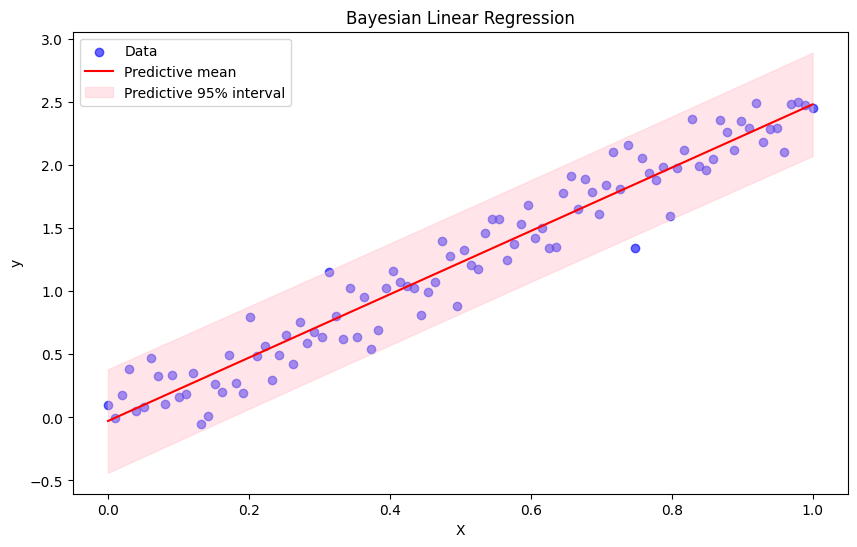

Posterior mean (w0 bias, w1 slope): [-0.02842106  2.50932745]


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

np.random.seed(42)

# Generate synthetic linear data
X = np.linspace(0, 1, 100).reshape(-1, 1)
y = 2.5 * X.squeeze() + np.random.normal(0, 0.2, X.shape[0])

# Train / test split (keeps same as PDF)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

class BayesianLinearRegression:
    def __init__(self, alpha=1.0, beta=1.0):
        # alpha: prior precision (1 / prior variance)
        # beta: noise precision (1 / noise variance)
        self.alpha = alpha
        self.beta = beta
        self.w_mean = None
        self.w_cov = None

    def fit(self, X, y):
        # Add bias term
        X_design = np.hstack((np.ones((X.shape[0], 1)), X))
        # Prior precision matrix
        S0_inv = self.alpha * np.eye(X_design.shape[1])
        # Posterior precision
        SN_inv = S0_inv + self.beta * (X_design.T @ X_design)
        # Posterior covariance
        SN = np.linalg.inv(SN_inv)
        # Posterior mean
        mN = self.beta * SN @ X_design.T @ y
        self.w_mean = mN
        self.w_cov = SN

    def predict(self, X, return_std=False):
        X_design = np.hstack((np.ones((X.shape[0], 1)), X))
        mean = X_design @ self.w_mean
        if return_std:
            # predictive variance = 1/beta + x^T * cov * x  (for each row)
            var = 1.0 / self.beta + np.sum((X_design @ self.w_cov) * X_design, axis=1)
            return mean, np.sqrt(var)
        return mean

# Fit model
blr = BayesianLinearRegression(alpha=1.0, beta=25.0)  # beta large => small noise variance
blr.fit(X_train, y_train)

# Predictions over a dense grid for plotting
X_pred = np.linspace(0, 1, 200).reshape(-1, 1)
y_pred_mean, y_pred_std = blr.predict(X_pred, return_std=True)

# Plot
plt.figure(figsize=(10, 6))
plt.scatter(X, y, label="Data", color="blue", alpha=0.6)
plt.plot(X_pred, y_pred_mean, label="Predictive mean", color="red")
plt.fill_between(
    X_pred.squeeze(),
    y_pred_mean - 2 * y_pred_std,
    y_pred_mean + 2 * y_pred_std,
    color="pink",
    alpha=0.4,
    label="Predictive 95% interval",
)
plt.title("Bayesian Linear Regression")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

# print estimates
print("Posterior mean (w0 bias, w1 slope):", blr.w_mean)